# Segun el analisis de datos , procedemos a responder las siguientes preguntas

## Pregunta 1: ¿Qué tipo de contrato tiene más churn?
El tipo de contrato  Month-to-month    0.427097
el contrato con el número más alto es donde más clientes se van es de Month-to-month con 42.7%.

## Pregunta 2: ¿Los clientes nuevos se van más?

Los clientes nuevos que mas se van son el 17.97% y los que se quedaron son el 37.56%.

## Pregunta 3: ¿Qué método de pago tiene más churn?

El metodo de pago que tiene mas churn es de Electronic check con un 45.2%

## Pregunta 4: ¿Tener soporte técnico reduce la fuga?

No, debido a que el 15.16% solo opta del soporte tecnico y el 7.4% no tiene el acceso a los servicios de internet. 

## Pregunta 5: ¿Los cargos altos se relacionan con irse?
Segun los graficos obtenido se tiene que los cargos son de 74.44%, la cuales son las personas que pagaban mas.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\pc\churn-project\WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
df.info()
df.head()

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")
df["TotalCharges"]=df["TotalCharges"].fillna(0)

In [3]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [4]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [11]:
df["churn_num"]=df["Churn"].replace({"Yes":1,"No":0})
df["churn_num"]

C:\Users\pc\AppData\Local\Temp\ipykernel_3580\3378610076.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["churn_num"]=df["Churn"].replace({"Yes":1,"No":0})


0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: churn_num, Length: 7043, dtype: int64

In [6]:
resultado=df.groupby("Contract")["churn_num"].mean()
resultado

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: churn_num, dtype: float64

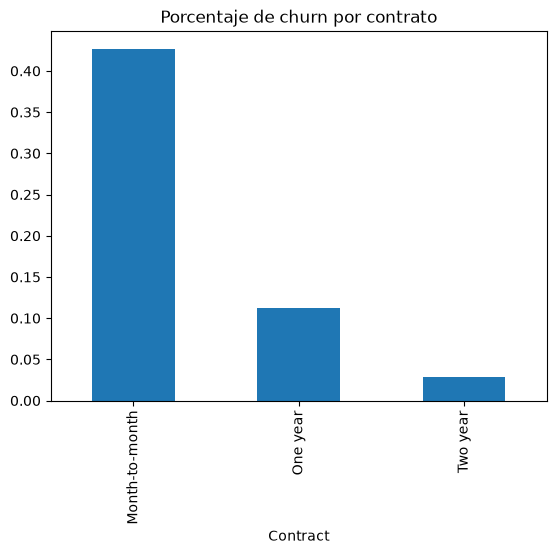

In [10]:
resultado.plot(kind="bar")
plt.title("Porcentaje de churn por contrato")
plt.show()

PaymentMethod
Bank transfer (automatic)    0.167098
Credit card (automatic)      0.152431
Electronic check             0.452854
Mailed check                 0.191067
Name: churn_num, dtype: float64


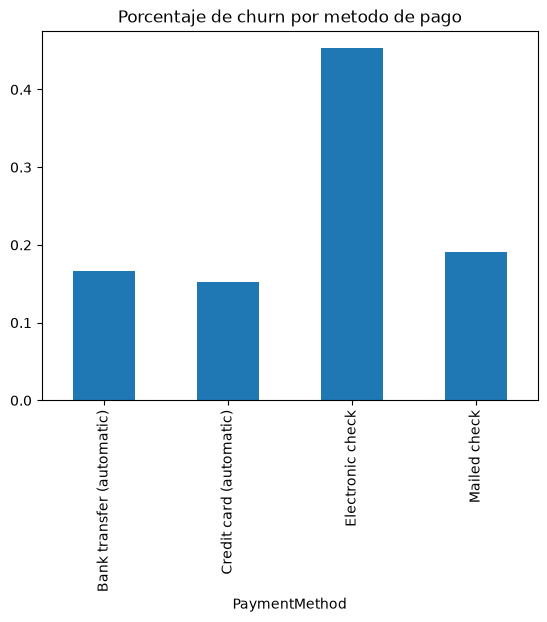

In [19]:
resultado=df.groupby("PaymentMethod")["churn_num"].mean()
resultado.plot(kind="bar")
print(resultado)
plt.title("Porcentaje de churn por metodo de pago")
plt.show()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


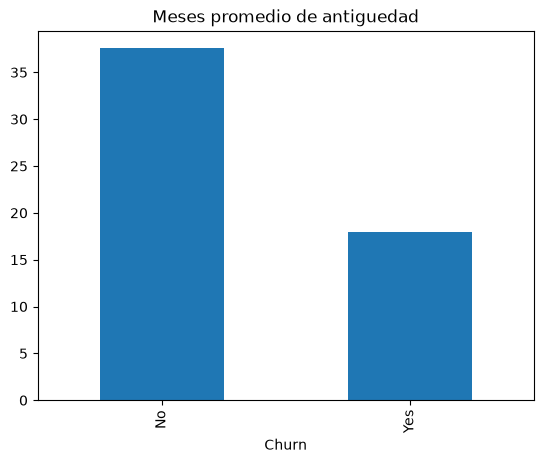

In [20]:
resultado=df.groupby("Churn")["tenure"].mean()
resultado.plot(kind="bar")
print(resultado)
plt.title("Meses promedio de antiguedad")
plt.show()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


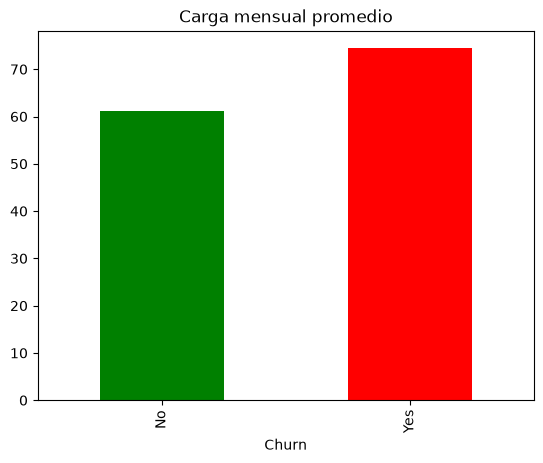

In [22]:
resultado=df.groupby("Churn")["MonthlyCharges"].mean()
resultado.plot(kind="bar", color=["green","red"])
print(resultado)
plt.title("Carga mensual promedio")
plt.show()

In [24]:
resultado=df.groupby("TechSupport")["churn_num"].mean()*100
print(resultado)

TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: churn_num, dtype: float64
